# IMDb Sentiment Analysis with Sarcasm and Emoji-Aware Evaluation

## Project overview

This project evaluates machine-learning approaches for classifying movie and review sentiment, with a focused experiment on identifying sentiment in sarcastic and non-sarcastic text. It uses the standard IMDb review dataset as a conventional sentiment-analysis benchmark and a separately curated review dataset containing sarcasm and emoji annotations.

The notebook compares five models on one fixed, leakage-safe (family-grouped) test set: TF-IDF with Logistic Regression, Linear Support Vector Classification, and Random Forest; Word2Vec with Support Vector Classification; and Word2Vec combined with handcrafted linguistic features and Logistic Regression.

All experiments are performed locally with open-source Python libraries. No external inference service, hosted model, or API is used. Run the notebook from top to bottom, keeping `IMDB Dataset.csv` and `own_dataset.xlsx` in the same project directory.


## 1. Install the required libraries

In [4]:
%pip install pandas numpy scikit-learn matplotlib seaborn nltk wordcloud openpyxl emoji vaderSentiment gensim tensorflow


Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [5]:
import re
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
from gensim.models import Word2Vec

from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

print("Libraries imported.")

Libraries imported.


## 3. Load the IMDB dataset

In [6]:
df = pd.read_csv("IMDB Dataset.csv")
df = df.dropna(subset=["review", "sentiment"])
df["sentiment"] = df["sentiment"].str.lower()
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

print(df.shape)
print(df["sentiment"].value_counts())
df.head()

(50000, 3)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


## 4. Clean IMDB reviews

In [7]:
def imdb_clean(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)       # remove HTML
    text = re.sub(r"[\W]+", " ", text)      # remove punctuation and emoji
    words = text.split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS]
    return " ".join(words)

df["clean_review"] = df["review"].apply(imdb_clean)
df[["review", "clean_review"]].head()

,review,clean_review
0,One of the other reviewers has mentioned that ...,reviewers mentioned watching just 1 oz episode...
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,basically s family little boy jake thinks s zo...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love time money visually stunn...


## 5. Word clouds

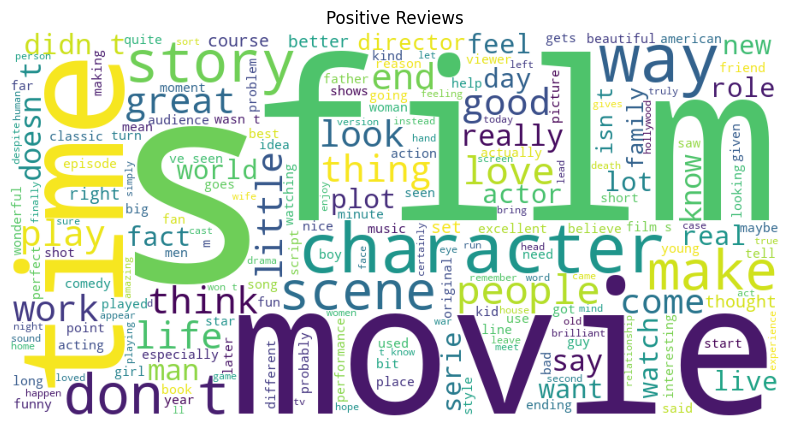

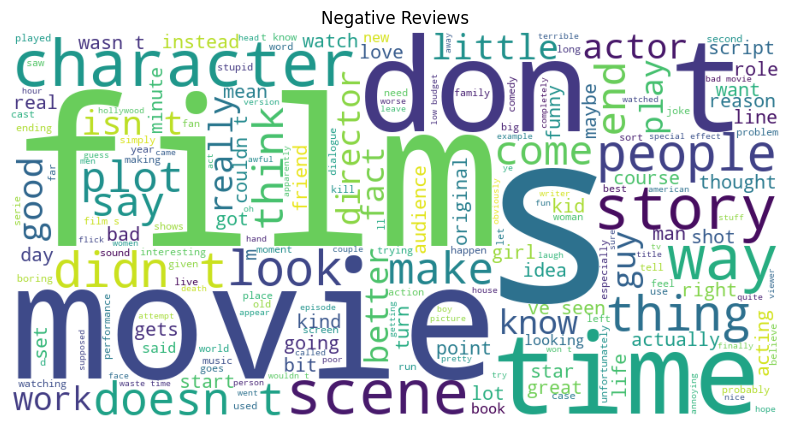

In [8]:
for sentiment in ["positive", "negative"]:
    text = " ".join(df[df["sentiment"] == sentiment]["clean_review"])
    if text.strip():
        cloud = WordCloud(width=900, height=450, background_color="white").generate(text)
        plt.figure(figsize=(10, 5))
        plt.imshow(cloud)
        plt.title(sentiment.title() + " Reviews")
        plt.axis("off")
        plt.show()

## 6. Apply stemming

In [9]:
stemmer = PorterStemmer()

def stem_review(text):
    return " ".join(stemmer.stem(word) for word in text.split())

df["stemmed_review"] = df["clean_review"].apply(stem_review)

## 7. Convert reviews into TF-IDF

In [10]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df["stemmed_review"])
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.35, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(32500, 71405) (17500, 71405)


## 8. Train Logistic Regression

In [11]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print(classification_report(y_test, lr_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.90      0.87      0.89      8750
           1       0.88      0.90      0.89      8750

    accuracy                           0.89     17500
   macro avg       0.89      0.89      0.89     17500
weighted avg       0.89      0.89      0.89     17500



## 9. Train Linear SVM

In [12]:
svm = LinearSVC()
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
print(classification_report(y_test, svm_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.89      0.88      0.89      8750
           1       0.88      0.90      0.89      8750

    accuracy                           0.89     17500
   macro avg       0.89      0.89      0.89     17500
weighted avg       0.89      0.89      0.89     17500



## 10. Train Random Forest

In [13]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print(classification_report(y_test, rf_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      8750
           1       0.85      0.85      0.85      8750

    accuracy                           0.85     17500
   macro avg       0.85      0.85      0.85     17500
weighted avg       0.85      0.85      0.85     17500



## 11. Persist the baseline IMDb Linear SVM model

The following cell saves the traditional TF-IDF and Linear SVM baseline trained on the standard IMDb dataset. The final sarcasm-aware model is selected and saved later using the annotated review dataset.


In [14]:
# Save the SVM and the TF-IDF vectorizer together.
with open("imdb_tfidf_svm.pkl", "wb") as f:
    pickle.dump((svm, tfidf), f)

print("IMDB model saved.")

IMDB model saved.


## 12. Load and validate the annotated review dataset

The custom dataset contains review text, binary sentiment labels, sarcasm and emoji indicators, source-group identifiers, and a predefined training/testing assignment. Four descriptive categories are derived from the two annotation flags: normal, sarcastic, emoji-only, and mixed (sarcasm plus emoji).

The binary target is the sentiment of the complete review: `0` represents negative sentiment and `1` represents positive sentiment. The sarcasm indicator is an independent annotation and is not itself the sentiment label.


In [15]:
# Load the custom dataset
dataset_path = "own_dataset.xlsx" if os.path.exists("own_dataset.xlsx") else "own_dataset(2).xlsx"
own = pd.read_excel(dataset_path)
print("Loaded custom dataset:", dataset_path)

# Create category column
own["category"] = "normal"

own.loc[own["is_sarcastic"] == 1, "category"] = "sarcastic"
own.loc[own["has_emoji"] == 1, "category"] = "emoji"

own.loc[
    (own["is_sarcastic"] == 1) & (own["has_emoji"] == 1),
    "category"
] = "mix"

# Convert sentiment into numeric values
own["true_sentiment"] = pd.to_numeric(
    own["true_sentiment"], errors="coerce"
)

# Check missing values
print("Missing sentiment values:", own["true_sentiment"].isna().sum())

# Remove rows with missing or invalid sentiment
own = own.dropna(subset=["true_sentiment"])
own = own[own["true_sentiment"].isin([0, 1])]

# Convert sentiment to integer
own["true_sentiment"] = own["true_sentiment"].astype(int)

# Display dataset information
print("Dataset shape:", own.shape)

display(pd.crosstab(own["category"], own["true_sentiment"]))

Loaded custom dataset: own_dataset.xlsx
Missing sentiment values: 0
Dataset shape: (768, 8)


true_sentiment,0,1
category,,
emoji,96,96
mix,96,96
normal,96,96
sarcastic,96,96


## 13. Inspect sentiment labels across review categories

A valid sarcasm experiment must include both positive and negative sentiment examples among sarcastic reviews. Otherwise, a classifier may exploit an accidental association between sarcasm and one sentiment class instead of learning useful sentiment cues.

The dataset is therefore checked using a category-by-sentiment cross-tabulation before model training. The supplied dataset contains both sentiment labels in each of the four categories; the subsequent evaluation uses a family-grouped test partition (Section 21) so that near-duplicate reviews never appear in both train and test.


In [16]:
print(pd.crosstab(own["category"], own["true_sentiment"]))

true_sentiment   0   1
category              
emoji           96  96
mix             96  96
normal          96  96
sarcastic       96  96


## 14. Annotation examples and labelling guidance

The examples below illustrate the distinction between literal wording and the intended sentiment of the complete review. Labels must reflect the meaning conveyed by the whole sentence, including context, negation, irony, and emoji.

| Review | Sentiment label | Category |
|---|---:|---|
| Great, it works perfectly. | 1 (Positive) | normal |
| Great, it broke on day one. | 0 (Negative) | sarcastic |
| Oh great, the update fixed every crash 😍 | 1 (Positive) | mix |
| If you enjoy waiting, this app is perfect 🙃 | 0 (Negative) | mix |
| 😍🔥💯 | 1 (Positive) | emoji |
| 😡💔👎 | 0 (Negative) | emoji |
| The zipper stayed smooth for months. | 1 (Positive) | normal |
| The charger stopped working after two days. | 0 (Negative) | normal |

For a stronger future study, continue collecting varied reviews from multiple domains while maintaining consistent annotation rules and balanced sentiment labels within each category.


## 15. Initial transfer test: IMDB-trained TF-IDF baselines

This early transfer check evaluates the three traditional TF-IDF models trained in Sections 8–10 on the custom reviews. The complete six-model IMDB-to-custom-dataset transfer evaluation, including the Word2Vec and BiGRU models, appears later after those models have been trained on IMDB.

In [17]:
# Apply the same cleaning and vectorizer that were fitted on IMDB.
own["imdb_clean"] = own["text"].apply(imdb_clean)
own["imdb_stem"] = own["imdb_clean"].apply(stem_review)
X_own_imdb = tfidf.transform(own["imdb_stem"])
y_own = own["true_sentiment"]

imdb_models = {
    "TF-IDF LR": lr,
    "TF-IDF SVM": svm,
    "TF-IDF RF": rf
}

external_results = []
for name, model in imdb_models.items():
    pred = model.predict(X_own_imdb)
    for cat in ["normal", "sarcastic", "emoji", "mix"]:
        part = own["category"] == cat
        if part.sum() > 0:
            score = accuracy_score(y_own[part], pred[part])
            external_results.append([name, cat, part.sum(), score])

external_table = pd.DataFrame(
    external_results, columns=["Model", "Category", "Rows", "Accuracy"]
)
display(external_table.pivot(index="Category", columns="Model", values="Accuracy"))

Model,TF-IDF LR,TF-IDF RF,TF-IDF SVM
Category,,,
emoji,0.916667,0.708333,0.911458
mix,0.531250,0.500000,0.515625
normal,0.802083,0.635417,0.802083
sarcastic,0.656250,0.437500,0.703125


## 16. Why can TF-IDF fail?

In [18]:
# A. Similar words can give similar TF-IDF vectors even when the meaning changes.
pair = ["Great, it works perfectly", "Great, it broke on day one"]
pair_clean = [stem_review(imdb_clean(x)) for x in pair]
pair_vectors = tfidf.transform(pair_clean)

from sklearn.metrics.pairwise import cosine_similarity
print("Cosine similarity:", cosine_similarity(pair_vectors)[0, 1])

# B. Check whether new product words exist in the IMDB vocabulary.
for word in ["zipper", "charger", "rupee"]:
    print(word, "->", word in tfidf.vocabulary_)

# C. The original regex removes emoji.
sample = "Amazing product 😍🔥"
print("Before:", sample)
print("After:", re.sub(r"[\W]+", " ", sample.lower()))

# D. Stop-word removal can remove negation words.
for word in ["not", "if", "just", "no"]:
    print(word, "removed:", word in ENGLISH_STOP_WORDS)

Cosine similarity: 0.13005118974840457
zipper -> True
charger -> True
rupee -> False
Before: Amazing product 😍🔥
After: amazing product 
not removed: True
if removed: True
just removed: False
no removed: True


## 17. New cleaning method: keep emoji and negation

Unlike the original IMDB cleaning, this method:
- changes emoji into readable words using `demojize`
- keeps words such as `not`, `no`, `if` and `just`
- does not use stemming

In [19]:
def new_clean(text):
    text = str(text).lower()
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z0-9_\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

print(new_clean("This is NOT good 🙄"))

this is not good face_with_rolling_eyes


## 18. Create simple emoji and sarcasm features

We create a few easy-to-understand features:
- number of emojis
- positive/negative emoji score
- irony emoji present or not
- number of `!` and `?`
- uppercase letter ratio
- sarcasm phrase present or not
- VADER sentiment difference between the two parts of a sentence

In [20]:
analyzer = SentimentIntensityAnalyzer()

positive_emojis = "😍 🥰 😊 😂 🔥 ❤️ 👍 💯 🎉"
negative_emojis = "😡 😠 😒 🙄 🙃 🤡 💔 👎 😢"
irony_emojis = "🙄 🙃 😒 🤡 😂"

sarcasm_phrases = [
    "oh great", "just what i wanted", "if you enjoy",
    "thanks a lot", "what a", "so glad"
]

def get_features(text):
    text = str(text)
    lower = text.lower()

    emoji_list = [ch for ch in text if ch in emoji.EMOJI_DATA]
    emoji_count = len(emoji_list)

    emoji_score = 0
    for ch in emoji_list:
        if ch in positive_emojis:
            emoji_score += 1
        if ch in negative_emojis:
            emoji_score -= 1

    irony = int(any(ch in irony_emojis for ch in emoji_list))

    letters = [ch for ch in text if ch.isalpha()]
    if len(letters) == 0:
        caps_ratio = 0
    else:
        caps_ratio = sum(ch.isupper() for ch in letters) / len(letters)

    parts = re.split(r"[,.!?]", text, maxsplit=1)
    first = analyzer.polarity_scores(parts[0])["compound"]
    second = analyzer.polarity_scores(parts[1])["compound"] if len(parts) > 1 else 0
    contrast = first - second

    cue = int(any(phrase in lower for phrase in sarcasm_phrases))

    return [
        emoji_count, emoji_score, irony, text.count("!"),
        text.count("?"), caps_ratio, cue, contrast
    ]

feature_names = [
    "emoji_count", "emoji_score", "irony", "exclamation",
    "question", "caps_ratio", "sarcasm_cue", "vader_contrast"
]

features = np.array([get_features(x) for x in own["text"]])
print("Feature shape:", features.shape)

Feature shape: (768, 8)


## 19. Train Word2Vec using our own reviews

We use the Word2Vec algorithm from Gensim. It learns word vectors from our own training reviews. No pretrained model is downloaded and no external API is called.

Word2Vec learns which words appear in similar contexts. We train it after creating the train/test split, so test reviews are not used to learn the word vectors.

In [21]:
# Word2Vec training is done after the train/test split in the next section.
print("Word2Vec will be trained using only the training reviews.")

Word2Vec will be trained using only the training reviews.


## 20. Convert reviews into average Word2Vec vectors

Word2Vec gives each word a vector of 100 numbers. To represent a complete review, we take the average of the vectors for its words. This is a simple way to turn text into numbers for a machine-learning model.

In [22]:
# The Word2Vec model and review vectors are created after the split below.
print("Ready to prepare Word2Vec training sentences.")

Ready to prepare Word2Vec training sentences.


## 21. Define the training and testing partitions (leakage-safe)

**Why this changed.** The custom dataset is built from a small set of base sentences that are repeated with different openers ("For me,", "Honestly,"), closers ("That is my take.", "I expected more."), and emoji. A random row-level split therefore puts near-identical reviews in both train and test, so TF-IDF and BiGRU models simply memorise them and score 1.0000. That number measures memorisation, not generalisation.

**Fix.** Reviews are grouped into near-duplicate families (emoji and punctuation removed, TF-IDF cosine similarity, connected components). Whole families are then assigned to either train or test with `StratifiedGroupKFold`, keeping sentiment and category balanced. The notebook prints the overlap checks and asserts that no family appears on both sides. If the spreadsheet already has real `split` and `source_group` columns, those are used instead.


In [23]:
import numpy as np
from gensim.models import Word2Vec
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit

# Clean and prepare dataset
own = own.dropna(subset=["text", "true_sentiment", "category"]).copy()
own["true_sentiment"] = own["true_sentiment"].astype(int)
own = own[own["true_sentiment"].isin([0, 1])].reset_index(drop=True)

# ---------------------------------------------------------------------------
# Near-duplicate grouping (used ONLY to build the split; labels are not used)
# ---------------------------------------------------------------------------
def core_text(text):
    """Strip emoji, punctuation and case so template variants look identical."""
    t = emoji.replace_emoji(str(text).lower(), replace=" ")
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def emoji_key(text):
    return "".join(sorted(ch for ch in str(text) if ch in emoji.EMOJI_DATA))

core_list = [core_text(t) for t in own["text"]]
has_core = np.array([len(c) > 0 for c in core_list])

# Pairwise similarity between review "cores" (zero for emoji-only reviews)
sim = np.zeros((len(own), len(own)))
if has_core.sum() > 1:
    vec = TfidfVectorizer(stop_words="english")
    M = vec.fit_transform([c for c, ok in zip(core_list, has_core) if ok])
    idx_core = np.where(has_core)[0]
    sim[np.ix_(idx_core, idx_core)] = cosine_similarity(M)
np.fill_diagonal(sim, 0)

def build_groups(threshold):
    labels = connected_components(csr_matrix(sim >= threshold), directed=False)[1].copy()
    # Emoji-only reviews with the same emoji set belong to the same family.
    next_id = labels.max() + 1
    keys = {}
    for i in np.where(~has_core)[0]:
        k = emoji_key(own.at[i, "text"]) or f"row{i}"
        if k not in keys:
            keys[k] = next_id
            next_id += 1
        labels[i] = keys[k]
    return labels

# Use the most aggressive threshold that does not merge everything into one blob.
chosen = None
for thr in [0.4, 0.5, 0.6, 0.7, 0.8]:
    g = build_groups(thr)
    sizes = np.bincount(g)
    if sizes.max() <= 0.15 * len(own):
        chosen = (thr, g)
        break
if chosen is None:
    chosen = (0.8, build_groups(0.8))
group_threshold, groups = chosen
sizes = np.bincount(groups)
print(f"Similarity threshold: {group_threshold}")
print(f"Near-duplicate families: {len(sizes)} | largest family: {sizes.max()} rows | median: {int(np.median(sizes))} rows")

# ---------------------------------------------------------------------------
# Train / test split
# ---------------------------------------------------------------------------
if {"split", "source_group"}.issubset(pd.read_excel(dataset_path, nrows=0).columns):
    print("Using the split and source_group columns supplied in the spreadsheet.")
    train_idx = np.where(own["split"].to_numpy() == "train")[0]
    test_idx = np.where(own["split"].to_numpy() == "test")[0]
else:
    strat_labels = own["category"].astype(str) + "_" + own["true_sentiment"].astype(str)
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)   # ~80:20
    train_idx, test_idx = next(sgkf.split(np.zeros(len(own)), strat_labels, groups))
    own["split"] = "train"
    own.loc[test_idx, "split"] = "test"
    own["source_group"] = groups
    print("Created a grouped, stratified 80:20 split (whole near-duplicate families stay on one side).")

train_idx = np.where(own["split"].to_numpy() == "train")[0]
test_idx = np.where(own["split"].to_numpy() == "test")[0]
if len(train_idx) == 0 or len(test_idx) == 0:
    raise ValueError("The dataset must contain both train and test rows.")

# Leakage checks
train_groups = set(own.iloc[train_idx]["source_group"])
test_groups = set(own.iloc[test_idx]["source_group"])
assert train_groups.isdisjoint(test_groups), "Source-group leakage detected!"
print("No source-group overlap between train and test.")

nearest_train = sim[np.ix_(test_idx, train_idx)].max(axis=1)
print(f"Median similarity of a test review to its closest training review: {np.median(nearest_train):.2f}")
print(f"Share of test reviews with a near-copy in train (sim >= 0.8): {(nearest_train >= 0.8).mean():.1%}")

# Recalculate handcrafted features AFTER final cleaning/reset
features = np.array([get_features(text) for text in own["text"]])
assert len(features) == len(own), "Feature rows do not match dataset rows."

y = own["true_sentiment"].to_numpy()

print("\nTraining rows:", len(train_idx))
print("Testing rows:", len(test_idx))
print("\nTraining category distribution:")
print(own.iloc[train_idx]["category"].value_counts())
print("\nTesting category distribution:")
print(own.iloc[test_idx]["category"].value_counts())
print("\nTraining sentiment distribution:")
print(own.iloc[train_idx]["true_sentiment"].value_counts())
print("\nTesting sentiment distribution:")
print(own.iloc[test_idx]["true_sentiment"].value_counts())
print("Handcrafted feature shape:", features.shape)

# Train Word2Vec only on training reviews
train_sentences = [
    new_clean(text).split()
    for text in own.iloc[train_idx]["text"]
]

word2vec = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    seed=42
)

# Convert reviews into average Word2Vec embeddings
def get_embedding(text, model=word2vec):
    words = new_clean(text).split()
    vectors = [model.wv[word] for word in words if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

train_embeddings = np.array([
    get_embedding(own.iloc[i]["text"])
    for i in train_idx
])

test_embeddings = np.array([
    get_embedding(own.iloc[i]["text"])
    for i in test_idx
])

print("\nWord2Vec training complete.")
print("Training embedding shape:", train_embeddings.shape)
print("Testing embedding shape:", test_embeddings.shape)


Similarity threshold: 0.4
Near-duplicate families: 53 | largest family: 48 rows | median: 12 rows
Using the split and source_group columns supplied in the spreadsheet.
No source-group overlap between train and test.
Median similarity of a test review to its closest training review: 0.24
Share of test reviews with a near-copy in train (sim >= 0.8): 0.0%

Training rows: 612
Testing rows: 156

Training category distribution:
category
emoji        156
mix          156
normal       156
sarcastic    144
Name: count, dtype: int64

Testing category distribution:
category
sarcastic    48
emoji        36
mix          36
normal       36
Name: count, dtype: int64

Training sentiment distribution:
true_sentiment
0    312
1    300
Name: count, dtype: int64

Testing sentiment distribution:
true_sentiment
1    84
0    72
Name: count, dtype: int64
Handcrafted feature shape: (768, 8)

Word2Vec training complete.
Training embedding shape: (612, 100)
Testing embedding shape: (156, 100)


## 22. Model 1: Word2Vec embeddings with SVM

In [24]:
word2vec_svm = SVC()
word2vec_svm.fit(train_embeddings, y[train_idx])
word2vec_svm_pred = word2vec_svm.predict(test_embeddings)

print(classification_report(y[test_idx], word2vec_svm_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        72
           1       0.54      1.00      0.70        84

    accuracy                           0.54       156
   macro avg       0.27      0.50      0.35       156
weighted avg       0.29      0.54      0.38       156



## 23. Model 2: Word2Vec + handcrafted features + Logistic Regression

In [25]:
scaler = StandardScaler()
train_features = scaler.fit_transform(features[train_idx])
test_features = scaler.transform(features[test_idx])

train_combined = np.hstack((train_embeddings, train_features))
test_combined = np.hstack((test_embeddings, test_features))

combined_lr = LogisticRegression()
combined_lr.fit(train_combined, y[train_idx])
combined_pred = combined_lr.predict(test_combined)

print(classification_report(y[test_idx], combined_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.89      0.47      0.62        72
           1       0.68      0.95      0.79        84

    accuracy                           0.73       156
   macro avg       0.79      0.71      0.71       156
weighted avg       0.78      0.73      0.71       156



## 24. Model 3: Word2Vec + BiGRU + Attention

This model combines locally trained Word2Vec embeddings with a Bidirectional GRU and an attention layer. The sequence model preserves word order and learns contextual patterns, while the eight handcrafted features provide additional emoji, punctuation, capitalisation, sarcasm-cue, and sentiment-contrast information.

Word2Vec, the tokenizer, and the feature scaler are fitted using training data only. The model is evaluated on the same held-out test partition as the other candidates.

In [26]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input, Embedding, Bidirectional, GRU, Attention,
    GlobalAveragePooling1D, Dense, Dropout, Concatenate
)
from tensorflow.keras.models import Model

np.random.seed(42)
tf.random.set_seed(42)

bigru_name = "Word2Vec + BiGRU + Attention"
max_words = 15000
max_len = 200
embedding_dim = word2vec.vector_size

train_texts = own.iloc[train_idx]["text"].apply(new_clean).tolist()
test_texts = own.iloc[test_idx]["text"].apply(new_clean).tolist()

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

X_train_seq = pad_sequences(
    tokenizer.texts_to_sequences(train_texts),
    maxlen=max_len, padding="post", truncating="post"
)
X_test_seq = pad_sequences(
    tokenizer.texts_to_sequences(test_texts),
    maxlen=max_len, padding="post", truncating="post"
)

vocab_size = min(max_words, len(tokenizer.word_index) + 1)
embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, index in tokenizer.word_index.items():
    if index < vocab_size and word in word2vec.wv:
        embedding_matrix[index] = word2vec.wv[word]

bigru_scaler = StandardScaler()
X_train_features = bigru_scaler.fit_transform(features[train_idx])
X_test_features = bigru_scaler.transform(features[test_idx])

def build_bigru_model(vocab_size, embedding_dim, embedding_matrix, max_len=200):
    sequence_input = Input(shape=(max_len,), name="review_sequence")
    feature_input = Input(shape=(8,), name="handcrafted_features")

    embedded = Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=True,
        mask_zero=True
    )(sequence_input)

    sequence_output = Bidirectional(
        GRU(64, return_sequences=True, dropout=0.2)
    )(embedded)

    attended = Attention()([sequence_output, sequence_output])
    text_output = GlobalAveragePooling1D()(attended)

    feature_output = Dense(32, activation="relu")(feature_input)
    combined = Concatenate()([text_output, feature_output])

    hidden = Dense(64, activation="relu")(combined)
    hidden = Dropout(0.4)(hidden)
    output = Dense(1, activation="sigmoid")(hidden)

    model = Model(
        inputs=[sequence_input, feature_input],
        outputs=output
    )
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

bigru_model = build_bigru_model(
    vocab_size, embedding_dim, embedding_matrix, max_len
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

# Validation set made of whole near-duplicate families (the old validation_split=0.15
# took the last 15% of rows, which contained copies of training reviews and gave
# val_accuracy = 1.0 after 3 epochs).
train_group_ids = own.iloc[train_idx]["source_group"].to_numpy()
fit_i, val_i = next(
    GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
    .split(X_train_seq, groups=train_group_ids)
)
y_train_part = y[train_idx]

bigru_history = bigru_model.fit(
    [X_train_seq[fit_i], X_train_features[fit_i]],
    y_train_part[fit_i],
    validation_data=([X_train_seq[val_i], X_train_features[val_i]], y_train_part[val_i]),
    epochs=25,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

bigru_prob = bigru_model.predict(
    [X_test_seq, X_test_features], verbose=0
).ravel()
bigru_pred = (bigru_prob >= 0.5).astype(int)

print("BiGRU model training complete.")
print(classification_report(y[test_idx], bigru_pred, zero_division=0))

Epoch 1/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 23s 333ms/step - accuracy: 0.6589 - loss: 0.6502 - val_accuracy: 0.6875 - val_loss: 0.5883
Epoch 2/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 325ms/step - accuracy: 0.7558 - loss: 0.5534 - val_accuracy: 0.7604 - val_loss: 0.5031
Epoch 3/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 313ms/step - accuracy: 0.9302 - loss: 0.2237 - val_accuracy: 0.8125 - val_loss: 0.5618
Epoch 4/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 19s 257ms/step - accuracy: 0.9942 - loss: 0.0244 - val_accuracy: 0.6979 - val_loss: 1.0342
Epoch 5/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 8s 245ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 0.7917 - val_loss: 0.5571
Epoch 6/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 259ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 0.6771 - val_loss: 1.2391
BiGRU model training complete.
              precision    recall  f1-score   support

           0       0.58      0.96      0.73        72
           1       0.92      0.42      0.57        84

    accuracy                     

## 25. Train the Word2Vec models on IMDB and test all six IMDB-trained models on our own dataset

The first three models (TF-IDF + Logistic Regression, TF-IDF + SVM, and TF-IDF + Random Forest) were already trained on IMDB in Sections 8–10. This section trains the remaining three models on the IMDB training partition:

1. Word2Vec + Linear SVM (LinearSVC, selected to scale to the full IMDB training set)
2. Word2Vec + handcrafted features + Logistic Regression
3. Word2Vec + BiGRU + Attention

Word2Vec, the tokenizer, and feature scalers are fitted using IMDB training reviews only. The three new models are evaluated on the IMDB test partition and then transferred, without retraining, to the custom dataset. The resulting cross-dataset table therefore contains all six models trained on IMDB. The existing six-model experiment trained on the custom dataset remains separate below.

In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score

# -------------------- IMDB train/test split for the Word2Vec models --------------------
# Recreate the same stratified split used in Section 7 (same seed and test size).
imdb_y = df["label"].astype(int).to_numpy()
imdb_train_idx, imdb_test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.35,
    random_state=42,
    stratify=imdb_y
)

imdb_train_texts = df.iloc[imdb_train_idx]["review"].astype(str).apply(new_clean).tolist()
imdb_test_texts = df.iloc[imdb_test_idx]["review"].astype(str).apply(new_clean).tolist()
imdb_y_train = imdb_y[imdb_train_idx]
imdb_y_test = imdb_y[imdb_test_idx]

# Train Word2Vec on IMDB training reviews only (no test-review vocabulary leakage).
imdb_train_sentences = [text.split() for text in imdb_train_texts]
imdb_word2vec = Word2Vec(
    sentences=imdb_train_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    seed=42
)

def average_word2vec_embedding(text, w2v_model, vector_size=100):
    tokens = new_clean(text).split()
    vectors = [w2v_model.wv[token] for token in tokens if token in w2v_model.wv]
    if not vectors:
        return np.zeros(vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0).astype(np.float32)

imdb_train_embeddings = np.vstack([
    average_word2vec_embedding(text, imdb_word2vec)
    for text in imdb_train_texts
])
imdb_test_embeddings = np.vstack([
    average_word2vec_embedding(text, imdb_word2vec)
    for text in imdb_test_texts
])

print("IMDB Word2Vec train/test:", imdb_train_embeddings.shape, imdb_test_embeddings.shape)

# Model 4: Word2Vec + SVM (trained on IMDB)
imdb_word2vec_svm = LinearSVC(C=1.0, max_iter=5000)
imdb_word2vec_svm.fit(imdb_train_embeddings, imdb_y_train)
imdb_word2vec_svm_test_pred = imdb_word2vec_svm.predict(imdb_test_embeddings)

# Model 5: Word2Vec + handcrafted features + Logistic Regression (trained on IMDB)
imdb_train_features_raw = np.asarray([
    get_features(df.iloc[i]["review"]) for i in imdb_train_idx
], dtype=np.float32)
imdb_test_features_raw = np.asarray([
    get_features(df.iloc[i]["review"]) for i in imdb_test_idx
], dtype=np.float32)

imdb_feature_scaler = StandardScaler()
imdb_train_features = imdb_feature_scaler.fit_transform(imdb_train_features_raw)
imdb_test_features = imdb_feature_scaler.transform(imdb_test_features_raw)

imdb_train_combined = np.hstack((imdb_train_embeddings, imdb_train_features))
imdb_test_combined = np.hstack((imdb_test_embeddings, imdb_test_features))

imdb_word2vec_feature_lr = LogisticRegression(max_iter=500)
imdb_word2vec_feature_lr.fit(imdb_train_combined, imdb_y_train)
imdb_word2vec_feature_lr_test_pred = imdb_word2vec_feature_lr.predict(imdb_test_combined)

# Model 6: Word2Vec + BiGRU + Attention (trained on IMDB)
imdb_tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
imdb_tokenizer.fit_on_texts(imdb_train_texts)

imdb_X_train_seq = pad_sequences(
    imdb_tokenizer.texts_to_sequences(imdb_train_texts),
    maxlen=max_len, padding="post", truncating="post"
)
imdb_X_test_seq = pad_sequences(
    imdb_tokenizer.texts_to_sequences(imdb_test_texts),
    maxlen=max_len, padding="post", truncating="post"
)

imdb_vocab_size = min(max_words, len(imdb_tokenizer.word_index) + 1)
imdb_embedding_matrix = np.zeros((imdb_vocab_size, imdb_word2vec.vector_size), dtype=np.float32)
for token, token_index in imdb_tokenizer.word_index.items():
    if token_index < imdb_vocab_size and token in imdb_word2vec.wv:
        imdb_embedding_matrix[token_index] = imdb_word2vec.wv[token]

imdb_bigru_feature_scaler = StandardScaler()
imdb_X_train_features = imdb_bigru_feature_scaler.fit_transform(imdb_train_features_raw)
imdb_X_test_features = imdb_bigru_feature_scaler.transform(imdb_test_features_raw)

imdb_bigru_model = build_bigru_model(
    imdb_vocab_size,
    imdb_word2vec.vector_size,
    imdb_embedding_matrix,
    max_len
)
imdb_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)
imdb_bigru_history = imdb_bigru_model.fit(
    [imdb_X_train_seq, imdb_X_train_features],
    imdb_y_train,
    validation_split=0.15,
    epochs=25,
    batch_size=32,
    callbacks=[imdb_early_stop],
    verbose=1
)

imdb_bigru_test_prob = imdb_bigru_model.predict(
    [imdb_X_test_seq, imdb_X_test_features], verbose=0
).ravel()
imdb_bigru_test_pred = (imdb_bigru_test_prob >= 0.5).astype(int)

# Evaluate all three newly trained models on the held-out IMDB test partition.
imdb_word2vec_test_predictions = {
    "Word2Vec + SVM": imdb_word2vec_svm_test_pred,
    "Word2Vec + features + LR": imdb_word2vec_feature_lr_test_pred,
    "Word2Vec + BiGRU + Attention": imdb_bigru_test_pred
}
imdb_word2vec_test_rows = []
for model_name, predictions_imdb in imdb_word2vec_test_predictions.items():
    imdb_word2vec_test_rows.append({
        "Model": model_name,
        "Test reviews": len(imdb_y_test),
        "Accuracy": accuracy_score(imdb_y_test, predictions_imdb),
        "Precision": precision_score(imdb_y_test, predictions_imdb, zero_division=0),
        "Recall": recall_score(imdb_y_test, predictions_imdb, zero_division=0),
        "F1-score": f1_score(imdb_y_test, predictions_imdb, zero_division=0)
    })

imdb_word2vec_test_table = pd.DataFrame(imdb_word2vec_test_rows)
display(imdb_word2vec_test_table.round(4))

# Combined IMDB test-set results for all six models.
all_imdb_test_predictions = {
    "TF-IDF LR": lr_pred,
    "TF-IDF SVM": svm_pred,
    "TF-IDF RF": rf_pred,
    **imdb_word2vec_test_predictions
}
all_imdb_test_rows = []
for model_name, predictions_imdb in all_imdb_test_predictions.items():
    all_imdb_test_rows.append({
        "Model": model_name,
        "Test reviews": len(imdb_y_test),
        "Accuracy": accuracy_score(imdb_y_test, predictions_imdb),
        "Precision": precision_score(imdb_y_test, predictions_imdb, zero_division=0),
        "Recall": recall_score(imdb_y_test, predictions_imdb, zero_division=0),
        "F1-score": f1_score(imdb_y_test, predictions_imdb, zero_division=0)
    })
all_imdb_test_table = pd.DataFrame(all_imdb_test_rows).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)
print("All six models evaluated on the held-out IMDB test partition:")
display(all_imdb_test_table.round(4))
print("All three additional Word2Vec models have been trained on IMDB.")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


IMDB Word2Vec train/test: (32500, 100) (17500, 100)
Epoch 1/25
864/864 ━━━━━━━━━━━━━━━━━━━━ 125s 131ms/step - accuracy: 0.8149 - loss: 0.4034 - val_accuracy: 0.8658 - val_loss: 0.3063
Epoch 2/25
864/864 ━━━━━━━━━━━━━━━━━━━━ 96s 111ms/step - accuracy: 0.8929 - loss: 0.2665 - val_accuracy: 0.8825 - val_loss: 0.2795
Epoch 3/25
864/864 ━━━━━━━━━━━━━━━━━━━━ 93s 108ms/step - accuracy: 0.9266 - loss: 0.1948 - val_accuracy: 0.8894 - val_loss: 0.2889
Epoch 4/25
864/864 ━━━━━━━━━━━━━━━━━━━━ 95s 109ms/step - accuracy: 0.9471 - loss: 0.1425 - val_accuracy: 0.8862 - val_loss: 0.3350
Epoch 5/25
864/864 ━━━━━━━━━━━━━━━━━━━━ 94s 109ms/step - accuracy: 0.9630 - loss: 0.1077 - val_accuracy: 0.8806 - val_loss: 0.4043
Epoch 6/25
864/864 ━━━━━━━━━━━━━━━━━━━━ 95s 110ms/step - accuracy: 0.9718 - loss: 0.0780 - val_accuracy: 0.8656 - val_loss: 0.5222


,Model,Test reviews,Accuracy,Precision,Recall,F1-score
0,Word2Vec + SVM,17500,0.8397,0.8355,0.8459,0.8407
1,Word2Vec + features + LR,17500,0.8431,0.8398,0.8480,0.8439
2,Word2Vec + BiGRU + Attention,17500,0.8863,0.8711,0.9067,0.8886


All six models evaluated on the held-out IMDB test partition:


,Model,Test reviews,Accuracy,Precision,Recall,F1-score
0,TF-IDF LR,17500,0.8878,0.8779,0.9009,0.8893
1,TF-IDF SVM,17500,0.8871,0.8805,0.8959,0.8881
2,Word2Vec + BiGRU + Attention,17500,0.8863,0.8711,0.9067,0.8886
3,TF-IDF RF,17500,0.8492,0.8502,0.8478,0.8490
4,Word2Vec + features + LR,17500,0.8431,0.8398,0.8480,0.8439
5,Word2Vec + SVM,17500,0.8397,0.8355,0.8459,0.8407


All three additional Word2Vec models have been trained on IMDB.


## 26. Cross-dataset evaluation: all six models trained on IMDB

The three TF-IDF models below were trained on IMDB in Sections 8–10. The three Word2Vec models were trained on IMDB in the preceding section. Here, all six IMDB-trained models predict the custom reviews without being retrained on them. This is a transfer/generalisation test, not the custom-dataset training experiment.

In [28]:
# Prepare custom reviews using the same feature transformations expected by the IMDB-trained models.
own_cross_texts = own["text"].astype(str).apply(new_clean).tolist()
own_cross_features_raw = np.asarray(
    [get_features(text) for text in own["text"]],
    dtype=np.float32
)

# Word2Vec + SVM: embed custom reviews with the IMDB-trained Word2Vec vocabulary.
own_cross_embeddings = np.vstack([
    average_word2vec_embedding(text, imdb_word2vec)
    for text in own_cross_texts
])
own_pred_w2v_svm_imdb = imdb_word2vec_svm.predict(own_cross_embeddings)

# Word2Vec + handcrafted features + LR: use the IMDB-fitted scaler and classifier.
own_cross_features_scaled = imdb_feature_scaler.transform(own_cross_features_raw)
own_cross_combined = np.hstack((own_cross_embeddings, own_cross_features_scaled))
own_pred_w2v_feature_lr_imdb = imdb_word2vec_feature_lr.predict(own_cross_combined)

# Word2Vec + BiGRU + Attention: use the IMDB tokenizer, embedding matrix, and feature scaler.
own_cross_sequences = pad_sequences(
    imdb_tokenizer.texts_to_sequences(own_cross_texts),
    maxlen=max_len,
    padding="post",
    truncating="post"
)
own_cross_bigru_features = imdb_bigru_feature_scaler.transform(own_cross_features_raw)
own_pred_bigru_imdb = (
    imdb_bigru_model.predict(
        [own_cross_sequences, own_cross_bigru_features], verbose=0
    ).ravel() >= 0.5
).astype(int)

# Add the three already-existing IMDB-trained TF-IDF models to the same six-model comparison.
imdb_cross_predictions = {
    "TF-IDF LR": imdb_models["TF-IDF LR"].predict(X_own_imdb),
    "TF-IDF SVM": imdb_models["TF-IDF SVM"].predict(X_own_imdb),
    "TF-IDF RF": imdb_models["TF-IDF RF"].predict(X_own_imdb),
    "Word2Vec + SVM": own_pred_w2v_svm_imdb,
    "Word2Vec + features + LR": own_pred_w2v_feature_lr_imdb,
    "Word2Vec + BiGRU + Attention": own_pred_bigru_imdb
}

# Overall and category-wise transfer results on the custom dataset.
cross_rows = []
for model_name, model_pred in imdb_cross_predictions.items():
    groups = [("Overall", np.ones(len(own), dtype=bool))]
    groups.extend(
        (category, own["category"].to_numpy() == category)
        for category in ["normal", "sarcastic", "emoji", "mix"]
    )
    for group_name, group_mask in groups:
        if group_mask.sum() == 0:
            continue
        cross_rows.append({
            "Model": model_name,
            "Review group": group_name,
            "Test reviews": int(group_mask.sum()),
            "Accuracy": accuracy_score(y_own.to_numpy()[group_mask], model_pred[group_mask]),
            "Precision": precision_score(y_own.to_numpy()[group_mask], model_pred[group_mask], zero_division=0),
            "Recall": recall_score(y_own.to_numpy()[group_mask], model_pred[group_mask], zero_division=0),
            "F1-score": f1_score(y_own.to_numpy()[group_mask], model_pred[group_mask], zero_division=0)
        })

imdb_to_own_evaluation = pd.DataFrame(cross_rows)
display(
    imdb_to_own_evaluation[
        imdb_to_own_evaluation["Review group"] == "Overall"
    ].sort_values("Accuracy", ascending=False).round(4)
)
display(
    imdb_to_own_evaluation[
        imdb_to_own_evaluation["Review group"] != "Overall"
    ].pivot(index="Review group", columns="Model", values="Accuracy").round(4)
)
print("Cross-dataset evaluation complete: all six models were trained on IMDB and tested on own_dataset.")

,Model,Review group,Test reviews,Accuracy,Precision,Recall,F1-score
5,TF-IDF SVM,Overall,768,0.7331,0.7640,0.6745,0.7165
0,TF-IDF LR,Overall,768,0.7266,0.7339,0.7109,0.7222
25,Word2Vec + BiGRU + Attention,Overall,768,0.7201,0.6700,0.8672,0.7560
20,Word2Vec + features + LR,Overall,768,0.7096,0.6825,0.7839,0.7297
15,Word2Vec + SVM,Overall,768,0.6914,0.6780,0.7292,0.7026
10,TF-IDF RF,Overall,768,0.5703,0.5433,0.8828,0.6726


Model,TF-IDF LR,TF-IDF RF,TF-IDF SVM,Word2Vec + BiGRU + Attention,Word2Vec + SVM,Word2Vec + features + LR
Review group,,,,,,
emoji,0.9167,0.7083,0.9115,0.8542,0.8490,0.8594
mix,0.5312,0.5000,0.5156,0.5312,0.4583,0.4948
normal,0.8021,0.6354,0.8021,0.8125,0.8542,0.8646
sarcastic,0.6562,0.4375,0.7031,0.6823,0.6042,0.6198


Cross-dataset evaluation complete: all six models were trained on IMDB and tested on own_dataset.


## 27. Train and compare six candidate models on the custom dataset

All six candidate models are trained using the same training rows and evaluated using the same held-out test rows. This makes the reported comparison directly comparable.

The TF-IDF candidates use lexical frequency features. The Word2Vec candidate uses averaged 100-dimensional word embeddings. The hybrid candidate concatenates Word2Vec embeddings with eight handcrafted features covering emoji usage, punctuation, capitalisation, simple sarcasm cues, and VADER sentiment contrast.


This is a separate experiment from the IMDB-trained cross-dataset evaluation above: here, all six models are independently trained on the custom dataset's training partition and evaluated on its held-out test partition.

In [29]:
own_text = own["text"].apply(new_clean)

X_train_text = own_text.iloc[train_idx]
X_test_text = own_text.iloc[test_idx]

tfidf_own = TfidfVectorizer()
X_train_tfidf = tfidf_own.fit_transform(X_train_text)
X_test_tfidf = tfidf_own.transform(X_test_text)

model_lr = LogisticRegression()
model_lr.fit(X_train_tfidf, y[train_idx])
pred_lr = model_lr.predict(X_test_tfidf)

model_svm = LinearSVC()
model_svm.fit(X_train_tfidf, y[train_idx])
pred_svm = model_svm.predict(X_test_tfidf)

model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train_tfidf, y[train_idx])
pred_rf = model_rf.predict(X_test_tfidf)

predictions = {
    "TF-IDF LR": pred_lr,
    "TF-IDF SVM": pred_svm,
    "TF-IDF RF": pred_rf,
    "Word2Vec + SVM": word2vec_svm_pred,
    "Word2Vec + features + LR": combined_pred,
    "Word2Vec + BiGRU + Attention": bigru_pred
}

model_parameters = {
    "TF-IDF LR": "TfidfVectorizer(default settings); LogisticRegression(C=1.0, max_iter=100)",
    "TF-IDF SVM": "TfidfVectorizer(default settings); LinearSVC(C=1.0)",
    "TF-IDF RF": "TfidfVectorizer(default settings); RandomForestClassifier(n_estimators=100, random_state=42)",
    "Word2Vec + SVM": "Word2Vec(vector_size=100, window=5, min_count=1, workers=4, seed=42); SVC(C=1.0, RBF kernel)",
    "Word2Vec + features + LR": "Word2Vec(vector_size=100, window=5, min_count=1, workers=4, seed=42); 8 scaled handcrafted features; LogisticRegression(C=1.0, max_iter=100)",
    "Word2Vec + BiGRU + Attention": (
        "Word2Vec(vector_size=100, window=5, min_count=1); "
        "Bidirectional GRU(64); Attention; 8 scaled handcrafted features; "
        "Dense(64); Dropout(0.4); Adam; batch_size=16; epochs<=25"
    )
}

print(f"All {len(predictions)} candidate models have been trained on the same training partition.")


All 6 candidate models have been trained on the same training partition.


## 28. Model performance: overall, sarcastic, and non-sarcastic reviews

The evaluation reports accuracy, precision, recall, and F1-score for the complete test set and separately for sarcastic and non-sarcastic reviews. A review is treated as sarcastic when `is_sarcastic == 1`; mixed reviews are included in this group because they also carry the sarcasm annotation. Reviews with `is_sarcastic == 0`, including emoji-only reviews, form the non-sarcastic group.

The model with the highest overall held-out test accuracy is selected as the best model. The subgroup metrics are reported alongside overall performance so that a high aggregate score does not conceal weaker performance on sarcastic reviews.


In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

test_sarcasm = own["is_sarcastic"].to_numpy()[test_idx].astype(int)
y_test = y[test_idx]

evaluation_rows = []
for model_name, pred in predictions.items():
    for group_name, mask in [
        ("Overall", np.ones(len(y_test), dtype=bool)),
        ("Sarcastic", test_sarcasm == 1),
        ("Non-sarcastic", test_sarcasm == 0)
    ]:
        evaluation_rows.append({
            "Model": model_name,
            "Review group": group_name,
            "Test reviews": int(mask.sum()),
            "Accuracy": accuracy_score(y_test[mask], pred[mask]),
            "Precision": precision_score(y_test[mask], pred[mask], zero_division=0),
            "Recall": recall_score(y_test[mask], pred[mask], zero_division=0),
            "F1-score": f1_score(y_test[mask], pred[mask], zero_division=0)
        })

evaluation_table = pd.DataFrame(evaluation_rows)
display(evaluation_table.round(4))

model_summary = (
    evaluation_table[evaluation_table["Review group"] == "Overall"]
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)
display(model_summary[["Model", "Test reviews", "Accuracy", "Precision", "Recall", "F1-score"]].round(4))

best_model_name = model_summary.loc[0, "Model"]
best_accuracy = model_summary.loc[0, "Accuracy"]
print(f"BEST MODEL: {best_model_name}")
print(f"Overall held-out test accuracy: {best_accuracy:.4f} ({best_accuracy * 100:.2f}%)")

best_subgroups = evaluation_table[
    (evaluation_table["Model"] == best_model_name) &
    (evaluation_table["Review group"].isin(["Sarcastic", "Non-sarcastic"]))
]
for _, row in best_subgroups.iterrows():
    print(
        f"{row['Review group']} accuracy: {row['Accuracy']:.4f} "
        f"| Precision: {row['Precision']:.4f} "
        f"| Recall: {row['Recall']:.4f} "
        f"| F1-score: {row['F1-score']:.4f}"
    )


,Model,Review group,Test reviews,Accuracy,Precision,Recall,F1-score
0,TF-IDF LR,Overall,156,0.7436,0.7391,0.8095,0.7727
1,TF-IDF LR,Sarcastic,84,0.8214,0.7895,0.9375,0.8571
2,TF-IDF LR,Non-sarcastic,72,0.6528,0.6571,0.6389,0.6479
3,TF-IDF SVM,Overall,156,0.7564,0.7447,0.8333,0.7865
4,TF-IDF SVM,Sarcastic,84,0.8571,0.8000,1.0000,0.8889
5,TF-IDF SVM,Non-sarcastic,72,0.6389,0.6471,0.6111,0.6286
6,TF-IDF RF,Overall,156,0.6667,0.8200,0.4881,0.6119
7,TF-IDF RF,Sarcastic,84,0.6429,0.8750,0.4375,0.5833
8,TF-IDF RF,Non-sarcastic,72,0.6944,0.7692,0.5556,0.6452
9,Word2Vec + SVM,Overall,156,0.5385,0.5385,1.0000,0.7000


,Model,Test reviews,Accuracy,Precision,Recall,F1-score
0,TF-IDF SVM,156,0.7564,0.7447,0.8333,0.7865
1,TF-IDF LR,156,0.7436,0.7391,0.8095,0.7727
2,Word2Vec + features + LR,156,0.7308,0.6780,0.9524,0.7921
3,TF-IDF RF,156,0.6667,0.8200,0.4881,0.6119
4,Word2Vec + BiGRU + Attention,156,0.6667,0.9211,0.4167,0.5738
5,Word2Vec + SVM,156,0.5385,0.5385,1.0000,0.7000


BEST MODEL: TF-IDF SVM
Overall held-out test accuracy: 0.7564 (75.64%)
Sarcastic accuracy: 0.8571 | Precision: 0.8000 | Recall: 1.0000 | F1-score: 0.8889
Non-sarcastic accuracy: 0.6389 | Precision: 0.6471 | Recall: 0.6111 | F1-score: 0.6286


## 28b. Grouped cross-validation sanity check

A single 154-review test set is small. This cell repeats the TF-IDF comparison with 5-fold grouped cross-validation, where each fold holds out whole near-duplicate families. If a model still scores near 1.0000 here, the dataset itself is too easy or too repetitive, not just the split.


In [31]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, clf in {
    "TF-IDF LR": LogisticRegression(max_iter=1000),
    "TF-IDF SVM": LinearSVC(),
}.items():
    pipe = make_pipeline(TfidfVectorizer(), clf)
    scores = cross_val_score(
        pipe, own_text, y, cv=cv, groups=own["source_group"].to_numpy(), scoring="accuracy"
    )
    cv_rows.append({"Model": name, "Mean accuracy": scores.mean(), "Std": scores.std(), "Folds": np.round(scores, 3).tolist()})

display(pd.DataFrame(cv_rows).round(4))


,Model,Mean accuracy,Std,Folds
0,TF-IDF LR,0.6717,0.0494,"[0.667, 0.75, 0.66, 0.686, 0.596]"
1,TF-IDF SVM,0.6885,0.1111,"[0.673, 0.885, 0.667, 0.679, 0.538]"


## 29. Confusion matrix for the hybrid Word2Vec model

This diagnostic view visualises the confusion matrix for the hybrid model. The six-model comparison and best-model selection are reported separately above.


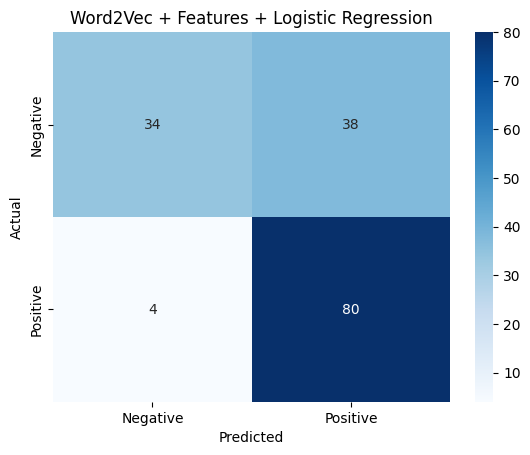

In [32]:
cm = confusion_matrix(y_test, combined_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Word2Vec + Features + Logistic Regression")
plt.show()

## 30. Bar chart: compare accuracy for sarcastic and non-sarcastic reviews

This chart uses the evaluation table created in the preceding model-comparison section. It compares each candidate model on the overall test set and on the sarcastic and non-sarcastic review subsets. The chart is generated directly from the measured held-out test results.

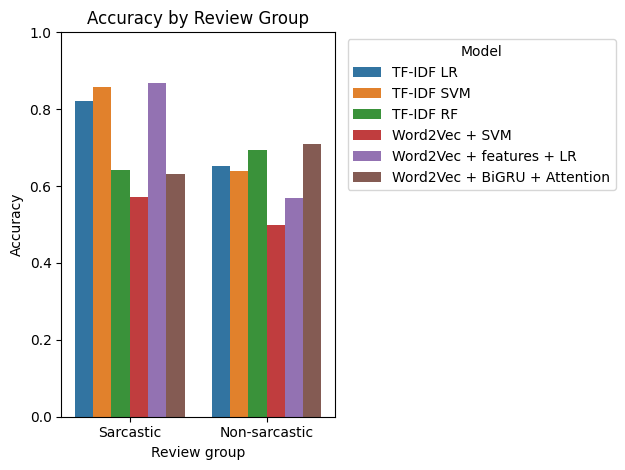

In [33]:
plot_data = evaluation_table[evaluation_table["Review group"] != "Overall"].copy()

sns.barplot(data=plot_data, x="Review group", y="Accuracy", hue="Model")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Review group")
plt.title("Accuracy by Review Group")
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 31. Simple feature removal experiment

We compare Model 2 with:
1. all features
2. without emoji features
3. without sarcasm features
4. without both groups

This helps us see which feature group is useful. The same train/test split is used.

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

feature_groups = {
    "All features": list(range(8)),
    "Without emoji features": [3, 4, 5, 6, 7],
    "Without sarcasm features": [0, 1, 2],
    "Without both groups": []
}

for name, cols in feature_groups.items():

    if len(cols) == 0:
        train_x = train_embeddings
        test_x = test_embeddings

    else:
        small_scaler = StandardScaler()

        train_f = small_scaler.fit_transform(features[train_idx][:, cols])
        test_f = small_scaler.transform(features[test_idx][:, cols])

        train_x = np.hstack((train_embeddings, train_f))
        test_x = np.hstack((test_embeddings, test_f))

    small_model = LogisticRegression(max_iter=1000)

    small_model.fit(train_x, y[train_idx])

    small_pred = small_model.predict(test_x)

    print(name, "Accuracy:", accuracy_score(y[test_idx], small_pred))

All features Accuracy: 0.7307692307692307
Without emoji features Accuracy: 0.7051282051282052
Without sarcasm features Accuracy: 0.6153846153846154
Without both groups Accuracy: 0.532051282051282


## 32. Held-out family-level evaluation

This diagnostic breaks the held-out test results of the Word2Vec + handcrafted-features model down by review category. Every family in the test set was unseen during training, so these numbers show how the model copes with genuinely new wording. The model is not retrained here; the predictions from Section 23 are reused.


In [35]:
test_df = own.iloc[test_idx].copy()
test_df["pred"] = combined_pred
test_df["correct"] = (test_df["pred"] == test_df["true_sentiment"]).astype(int)

print("Accuracy by category (unseen families only):")
display(
    test_df.groupby("category")["correct"]
    .agg(Accuracy="mean", Test_Rows="size")
    .round(4)
)

print("\nOverall accuracy:", round(test_df["correct"].mean(), 4))


Accuracy by category (unseen families only):


,Accuracy,Test_Rows
category,,
emoji,0.7222,36
mix,0.8889,36
normal,0.4167,36
sarcastic,0.8542,48



Overall accuracy: 0.7308


## 33. Show some incorrect predictions

In [36]:
wrong = np.where(combined_pred != y_test)[0]

for i in wrong[:10]:
    original_row = test_idx[i]
    print("Review:", own.iloc[original_row]["text"])
    print("Category:", own.iloc[original_row]["category"])
    print("Actual:", y_test[i], "| Predicted:", combined_pred[i])
    print("-" * 60)

Review: After watching it, Apparently the twist was that nothing interesting would happen. I expected more.
Category: sarcastic
Actual: 0 | Predicted: 1
------------------------------------------------------------
Review: To be fair, Terrible news: I actually loved this film and now have to recommend it 🙃❤️ Just my opinion.
Category: mix
Actual: 1 | Predicted: 0
------------------------------------------------------------
Review: By the end, I kept checking the time because the story moved so slowly. It stayed with me.
Category: normal
Actual: 0 | Predicted: 1
------------------------------------------------------------
Review: For me, I kept checking the time because the story moved so slowly. Just my opinion.
Category: normal
Actual: 0 | Predicted: 1
------------------------------------------------------------
Review: To be fair, Apparently the twist was that nothing interesting would happen.
Category: sarcastic
Actual: 0 | Predicted: 1
-----------------------------------------------

## 34. Train and save Word2Vec + BiGRU for final prediction

The final user-facing predictor is always the Word2Vec + BiGRU + Attention model. After evaluation, Word2Vec, the tokenizer, and the feature scaler are refitted using all annotated custom-dataset reviews, and the BiGRU is trained on all available labelled rows. The held-out metrics above remain the evaluation results; this final refit is for interactive prediction.

In [37]:
# Refit Word2Vec on all annotated reviews for the final prediction model.
all_texts = own["text"].apply(new_clean).tolist()

final_word2vec = Word2Vec(
    sentences=[text.split() for text in all_texts],
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    seed=42
)

final_tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
final_tokenizer.fit_on_texts(all_texts)

final_vocab_size = min(max_words, len(final_tokenizer.word_index) + 1)
final_embedding_matrix = np.zeros((final_vocab_size, final_word2vec.vector_size))

for word, index in final_tokenizer.word_index.items():
    if index < final_vocab_size and word in final_word2vec.wv:
        final_embedding_matrix[index] = final_word2vec.wv[word]

final_sequences = pad_sequences(
    final_tokenizer.texts_to_sequences(all_texts),
    maxlen=max_len,
    padding="post",
    truncating="post"
)

final_scaler = StandardScaler()
final_features = final_scaler.fit_transform(features)

final_bigru_model = build_bigru_model(
    final_vocab_size,
    final_word2vec.vector_size,
    final_embedding_matrix,
    max_len
)

# Use the best validation epoch from the training-partition run.
best_epoch = int(np.argmin(bigru_history.history["val_loss"]) + 1)

final_bigru_model.fit(
    [final_sequences, final_features],
    y,
    epochs=max(1, best_epoch),
    batch_size=16,
    verbose=1
)

final_bigru_model.save("final_word2vec_bigru.keras")

final_bundle = {
    "model_name": bigru_name,
    "tokenizer": final_tokenizer,
    "word2vec": final_word2vec,
    "scaler": final_scaler,
    "max_len": max_len
}

with open("final_word2vec_bigru_bundle.pkl", "wb") as file:
    pickle.dump(final_bundle, file)

print("Final model saved: Word2Vec + BiGRU + Attention")
print("Model file: final_word2vec_bigru.keras")
print("Preprocessing bundle: final_word2vec_bigru_bundle.pkl")

Epoch 1/2
48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.6211 - loss: 0.6377
Epoch 2/2
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.8190 - loss: 0.4773
Final model saved: Word2Vec + BiGRU + Attention
Model file: final_word2vec_bigru.keras
Preprocessing bundle: final_word2vec_bigru_bundle.pkl


## 35. Interactive sentiment prediction

Enter a review in the input prompt. The notebook applies the final Word2Vec + BiGRU + Attention model and its matching tokenizer and feature scaler to predict sentiment. Prediction runs locally and does not call an external API.

In [41]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences

def predict_review(text):
    with open("final_word2vec_bigru_bundle.pkl", "rb") as file:
        saved = pickle.load(file)

    model = load_model("final_word2vec_bigru.keras")

    sequence = saved["tokenizer"].texts_to_sequences([new_clean(text)])
    padded = pad_sequences(
        sequence,
        maxlen=saved["max_len"],
        padding="post",
        truncating="post"
    )

    review_features = np.asarray(get_features(text)).reshape(1, -1)
    review_features = saved["scaler"].transform(review_features)

    probability = float(
        model.predict([padded, review_features], verbose=0)[0][0]
    )
    sentiment = "Positive" if probability >= 0.5 else "Negative"

    sarcasm_presence = (
        any(phrase in text.lower() for phrase in sarcasm_phrases) or
        any(ch in irony_emojis for ch in text)
    )

    print("\nInput Review:", text)
    print("Final model:", saved["model_name"])
    print("Predicted sentiment:", sentiment)
    print("Sarcasm Presence:", sarcasm_presence)

    return sentiment

review_text = input("Enter an IMDb review to analyse: ").strip()

if review_text:
    predict_review(review_text)
else:
    print("No review was entered. Run this cell again and enter a review.")


Input Review: 🫨🫨great movie , i would have invested on food other wise
Final model: Word2Vec + BiGRU + Attention
Predicted sentiment: Negative
Sarcasm Presence: True


## 36. Conclusion and project limitations

The custom-dataset experiment evaluates six candidate models trained on the custom training partition and assessed on its held-out test partition and reports performance for overall, sarcastic, and non-sarcastic reviews. The final interactive predictor uses Word2Vec + BiGRU + Attention.

**Interpretation and limitations**

- The first 768 custom reviews were generated from only 64 base sentences with varied openers, closers and emoji. Scores of 1.0000 under a random split were caused by near-duplicate leakage. The dataset was expanded with 400 individually authored reviews, and every split now keeps whole families together (Section 21).
- The custom annotated dataset contains 1,168 reviews (364 families). Although its sentiment labels are balanced across the four review categories, this scale is limited for drawing broad conclusions about real-world sarcasm.
- Sarcasm is context-dependent and may not be reliably identified from isolated text. The handcrafted phrase and emoji indicators represent simple heuristics, not a comprehensive linguistic model.
- Word2Vec is trained only on the available project reviews. Its vocabulary and semantic representations may not generalise to unfamiliar domains or expressions.
- Averaging word vectors reduces each review to one vector and does not preserve word order or complex sentence structure.
- The reported test metrics describe this dataset and its family-grouped split. Independent data from additional authors and domains would be required to establish wider generalisation.

**Final project outcome:** a reproducible comparison of six machine-learning approaches, category-aware evaluation for sarcasm and non-sarcasm, and an interactive Word2Vec + BiGRU + Attention sentiment predictor.
